# Лабораторна робота 10. Завдання 3. Аугментація і тонке налаштування на обмеженому наборі коти-собаки: ResNet50

## Завантаження набору даних з Google Диска

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import glob, shutil

# шукаємо архів dogs-vs-cats.zip з Kaggle у будь-якій папці Google Диска
found = glob.glob('/content/drive/MyDrive/**/dogs-vs-cats*.zip', recursive=True)
print(found)
assert found, 'Архів dogs-vs-cats.zip не знайдено на Google Диску'
shutil.copy(found[0], '/content/dogs-vs-cats.zip')

['/content/drive/MyDrive/dogs-vs-cats.zip']


'/content/dogs-vs-cats.zip'

In [3]:
!unzip -q -o /content/dogs-vs-cats.zip -d /content/dogs-vs-cats
!unzip -q -o /content/dogs-vs-cats/train.zip -d /content/dogs-vs-cats
!ls /content/dogs-vs-cats/train | wc -l

25000


## Обмежений набір даних: 2000 / 500 / 500 зображень кожного класу

In [4]:
%%writefile prepare_small_dataset.py
"""Підготовка обмеженого набору даних Dogs vs. Cats для лабораторної роботи 10.

З 25 000 зображень train.zip з Kaggle формується невеликий набір: по 2000 зображень кожного класу
для навчання, по 500 для перевірки і по 500 для тестування. Усі зображення в наборах різні.
"""
import os
import shutil

# Каталог з набором даних (розпакований train.zip з Kaggle)
data_dir = '/content/dogs-vs-cats/train'
# Каталог з даними для навчання
train_dir = 'train'
# Каталог з даними для перевірки
val_dir = 'val'
# Каталог з даними для тестування
test_dir = 'test'
# Кількість зображень одного класу в кожному наборі
nb_train, nb_val, nb_test = 2000, 500, 500


def create_directory(dir_name):
    """Створює каталог dir_name з підкаталогами cats і dogs (старий каталог видаляється)."""
    if os.path.exists(dir_name):
        shutil.rmtree(dir_name)
    os.makedirs(os.path.join(dir_name, "cats"))
    os.makedirs(os.path.join(dir_name, "dogs"))


def copy_images(start_index, end_index, source_dir, dest_dir):
    """Копіює зображення котів і собак з номерами від start_index до end_index у підкаталоги cats і dogs."""
    for i in range(start_index, end_index):
        shutil.copy2(os.path.join(source_dir, "cat." + str(i) + ".jpg"), os.path.join(dest_dir, "cats"))
        shutil.copy2(os.path.join(source_dir, "dog." + str(i) + ".jpg"), os.path.join(dest_dir, "dogs"))


for d in (train_dir, val_dir, test_dir):
    create_directory(d)

# 0-1999 - навчання, 2000-2499 - перевірка, 2500-2999 - тестування
copy_images(0, nb_train, data_dir, train_dir)
copy_images(nb_train, nb_train + nb_val, data_dir, val_dir)
copy_images(nb_train + nb_val, nb_train + nb_val + nb_test, data_dir, test_dir)

for d in (train_dir, val_dir, test_dir):
    print(d, ': cats -', len(os.listdir(os.path.join(d, "cats"))), ', dogs -', len(os.listdir(os.path.join(d, "dogs"))))


Writing prepare_small_dataset.py


In [5]:
!python prepare_small_dataset.py

train : cats - 2000 , dogs - 2000
val : cats - 500 , dogs - 500
test : cats - 500 , dogs - 500


## Структура каталогів

In [6]:
!find train val test -maxdepth 1 -type d | sort
!ls train/cats | head -3
!ls val/cats | head -3
!ls test/dogs | head -3

test
test/cats
test/dogs
train
train/cats
train/dogs
val
val/cats
val/dogs
cat.0.jpg
cat.1000.jpg
cat.1001.jpg
cat.2000.jpg
cat.2001.jpg
cat.2002.jpg
dog.2500.jpg
dog.2501.jpg
dog.2502.jpg


## Підключаємо бібліотеки

In [7]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD
from tensorflow.keras.utils import load_img, img_to_array

## Генератори з аугментацією і без неї

In [8]:
# найкращі параметри класифікатора ResNet50 з лабораторної роботи 9
CFG = {'dense': 512, 'dropout': 0.5, 'extra_dense': 128, 'optimizer': 'sgd', 'lr': 1e-3, 'batch': 25}
BATCH = CFG['batch']
EPOCHS = 15

In [9]:
img_width, img_height = 150, 150
input_shape = (img_width, img_height, 3)

# генератор з аугментацією для навчання (параметри з методички)
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                   rotation_range=40,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   fill_mode='nearest')
# генератор без аугментації: для перевірки, тестування і для навчання без аугментації
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)


def flow(datagen, directory, batch_size, shuffle):
    return datagen.flow_from_directory(directory, target_size=(img_width, img_height),
                                       batch_size=batch_size, class_mode='binary', shuffle=shuffle)


train_generator = flow(train_datagen, 'train', BATCH, True)
train_noaug_generator = flow(test_datagen, 'train', BATCH, True)
val_generator = flow(test_datagen, 'val', 50, False)
test_generator = flow(test_datagen, 'test', 50, False)
print(train_generator.class_indices)

Found 4000 images belonging to 2 classes.
Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


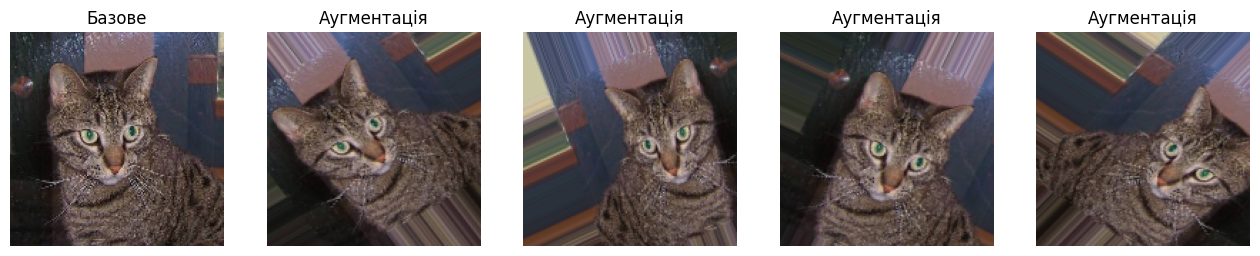

In [10]:
# як аугментація змінює одне зображення
img = load_img('train/cats/cat.1.jpg', target_size=(img_width, img_height))
x = np.expand_dims(img_to_array(img), axis=0)
plt.figure(figsize=(16, 4))
plt.subplot(1, 5, 1); plt.imshow(img); plt.title('Базове'); plt.axis('off')
aug_view = ImageDataGenerator(rotation_range=40, width_shift_range=0.2, height_shift_range=0.2,
                              zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
for i, batch in enumerate(aug_view.flow(x, batch_size=1)):
    plt.subplot(1, 5, i + 2); plt.imshow(batch[0].astype('uint8')); plt.title('Аугментація'); plt.axis('off')
    if i == 3:
        break
plt.show()

## Модель на основі ResNet50

In [11]:
def plot_history(history, title):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='навчальна')
    plt.plot(epochs_range, val_acc, label='перевірочна')
    plt.title(title + ': точність'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='навчальна')
    plt.plot(epochs_range, val_loss, label='перевірочна')
    plt.title(title + ': помилка (loss)'); plt.xlabel('Епоха'); plt.legend(); plt.grid()
    plt.show()

In [12]:



def load_base():
    # усереднення карт ознак, як у лабораторних 8 і 9
    net = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape, pooling='avg')
    net.trainable = False
    return net


def make_optimizer(name, lr):
    return Adam(learning_rate=lr) if name == 'adam' else SGD(learning_rate=lr)


def create_model(net):
    """Складена мережа: заморожена згорткова частина + класифікатор з найкращими параметрами лабораторної 9."""
    model = Sequential()
    model.add(Input(shape=input_shape))
    model.add(net)
    model.add(Flatten())
    model.add(Dense(CFG['dense'], activation='relu'))
    model.add(Dropout(CFG['dropout']))
    if CFG['extra_dense']:
        model.add(Dense(CFG['extra_dense'], activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer=make_optimizer(CFG['optimizer'], CFG['lr']), metrics=['accuracy'])
    return model


def train(generator, title):
    net = load_base()
    model = create_model(net)
    history = model.fit(generator, steps_per_epoch=len(generator), epochs=EPOCHS,
                        validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = model.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return model, net


def unfreeze(net, n_blocks):
    """Розморожуємо останні стадії ResNet50 (як у лабораторній 9), BatchNormalization залишаються замороженими."""
    stages = {1: ('conv5_',), 2: ('conv4_', 'conv5_')}[n_blocks]
    net.trainable = True
    for layer in net.layers:
        layer.trainable = layer.name.startswith(stages) and not isinstance(layer, BatchNormalization)


def fine_tune(model, net, n_blocks, title, epochs=5):
    """Тонке налаштування: розморожуємо n_blocks останніх блоків, мала швидкість навчання, як у лекції."""
    ft = create_model(load_base())
    ft.set_weights(model.get_weights())
    unfreeze(ft.layers[0], n_blocks)
    ft.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-5), metrics=['accuracy'])
    trainable = sum(int(np.prod(w.shape)) for w in ft.trainable_weights)
    print(f"Розморожено блоків: {n_blocks}, параметрів навчається: {trainable:,}")
    history = ft.fit(train_generator, steps_per_epoch=len(train_generator), epochs=epochs,
                     validation_data=val_generator, validation_steps=len(val_generator), verbose=2)
    plot_history(history, title)
    scores = ft.evaluate(test_generator, steps=len(test_generator), verbose=0)
    print(f"{title}: точність на тестових даних {scores[1]*100:.2f}%")
    results.append({'модель': title, 'навчальна, %': history.history['accuracy'][-1] * 100,
                    'перевірочна, %': history.history['val_accuracy'][-1] * 100, 'тестова, %': scores[1] * 100})
    return ft


results = []

## Перенесення навчання без аугментації

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
160/160 - 33s - 208ms/step - accuracy: 0.8232 - loss: 0.3986 - val_accuracy: 0.9540 - val_loss: 0.1449
Epoch 2/15
160/160 - 13s - 79ms/step - accuracy: 0.9333 - loss: 0.1838 - val_accuracy: 0.9600 - val_loss: 0.1025
Epoch 3/15
160/160 - 12s - 77ms/step - accuracy: 0.9388 - loss: 0.1580 - val_accuracy: 0.9610 - val_loss: 0.0891
Epoch 4/15
160/160 - 21s - 132ms/step - accuracy: 0.9477 - loss: 0.1281 - val_accuracy: 0.9620 - val_loss: 0.0811
Epoch 5/15
160/160 - 14s - 85ms/step - accuracy: 0.9542 - loss: 0.1166 - val_accuracy: 0.9640 - val_loss: 0.0780
Epoch 6/15
160/160 - 12s - 76ms/step - accuracy: 0.9550 - loss: 0.1157 - val_accuracy: 0.9670 - val_loss: 0.0745
Epoch 7/15
160/160 - 13s - 80ms/step - accuracy: 0.9620 - loss: 0.1043 - val_accuracy: 0.9660 - val_loss: 0.0759
Epoch 8/15
160/160 - 13s - 84ms/step - accuracy: 0.9655 - loss: 0.0991 - val_accuracy: 0.9690 - val_loss: 0.0723
Epoch 9/15
160/160 - 13s - 81ms/step - accu

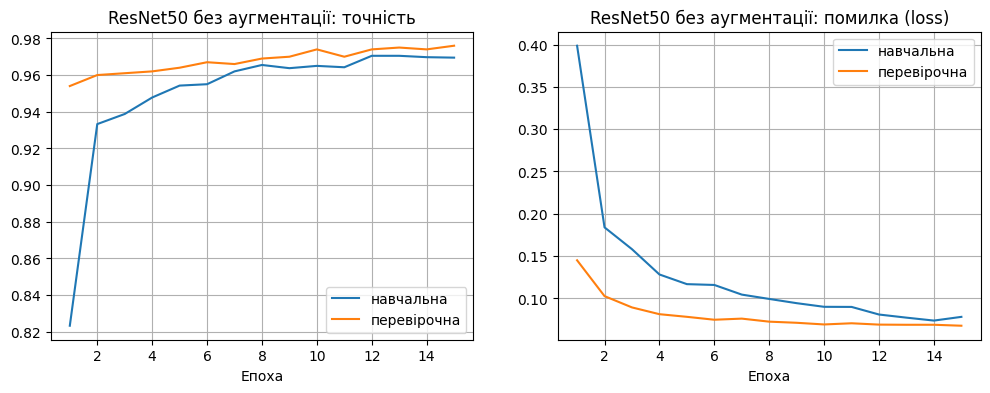

ResNet50 без аугментації: точність на тестових даних 96.90%


In [13]:
model_noaug, _ = train(train_noaug_generator, 'ResNet50 без аугментації')

## Перенесення навчання з аугментацією

Epoch 1/15
160/160 - 48s - 297ms/step - accuracy: 0.7508 - loss: 0.5130 - val_accuracy: 0.9440 - val_loss: 0.1840
Epoch 2/15
160/160 - 34s - 212ms/step - accuracy: 0.8903 - loss: 0.2786 - val_accuracy: 0.9640 - val_loss: 0.1237
Epoch 3/15
160/160 - 33s - 208ms/step - accuracy: 0.9032 - loss: 0.2380 - val_accuracy: 0.9690 - val_loss: 0.1000
Epoch 4/15
160/160 - 33s - 207ms/step - accuracy: 0.9187 - loss: 0.2036 - val_accuracy: 0.9720 - val_loss: 0.0867
Epoch 5/15
160/160 - 32s - 200ms/step - accuracy: 0.9172 - loss: 0.1983 - val_accuracy: 0.9720 - val_loss: 0.0806
Epoch 6/15
160/160 - 32s - 200ms/step - accuracy: 0.9237 - loss: 0.1848 - val_accuracy: 0.9730 - val_loss: 0.0779
Epoch 7/15
160/160 - 31s - 193ms/step - accuracy: 0.9305 - loss: 0.1704 - val_accuracy: 0.9750 - val_loss: 0.0732
Epoch 8/15
160/160 - 32s - 198ms/step - accuracy: 0.9330 - loss: 0.1587 - val_accuracy: 0.9760 - val_loss: 0.0690
Epoch 9/15
160/160 - 32s - 198ms/step - accuracy: 0.9348 - loss: 0.1629 - val_accuracy: 

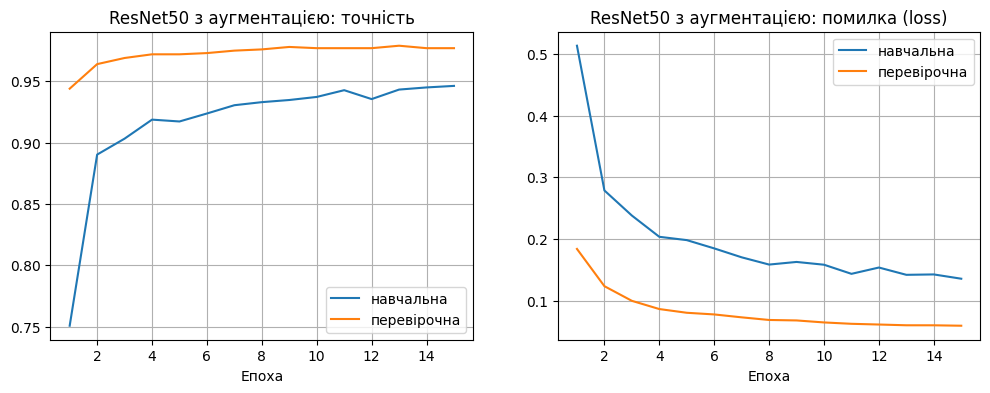

ResNet50 з аугментацією: точність на тестових даних 96.30%


In [14]:
model_aug, _ = train(train_generator, 'ResNet50 з аугментацією')

## Тонке налаштування: розморожено останню стадію (conv5), найкраще в лабораторній 9

Розморожено блоків: 1, параметрів навчається: 16,068,353
Epoch 1/5
160/160 - 57s - 359ms/step - accuracy: 0.9490 - loss: 0.1304 - val_accuracy: 0.9800 - val_loss: 0.0472
Epoch 2/5
160/160 - 34s - 211ms/step - accuracy: 0.9643 - loss: 0.0921 - val_accuracy: 0.9800 - val_loss: 0.0497
Epoch 3/5
160/160 - 35s - 221ms/step - accuracy: 0.9720 - loss: 0.0747 - val_accuracy: 0.9780 - val_loss: 0.0525
Epoch 4/5
160/160 - 33s - 207ms/step - accuracy: 0.9768 - loss: 0.0685 - val_accuracy: 0.9830 - val_loss: 0.0415
Epoch 5/5
160/160 - 34s - 214ms/step - accuracy: 0.9728 - loss: 0.0714 - val_accuracy: 0.9810 - val_loss: 0.0412


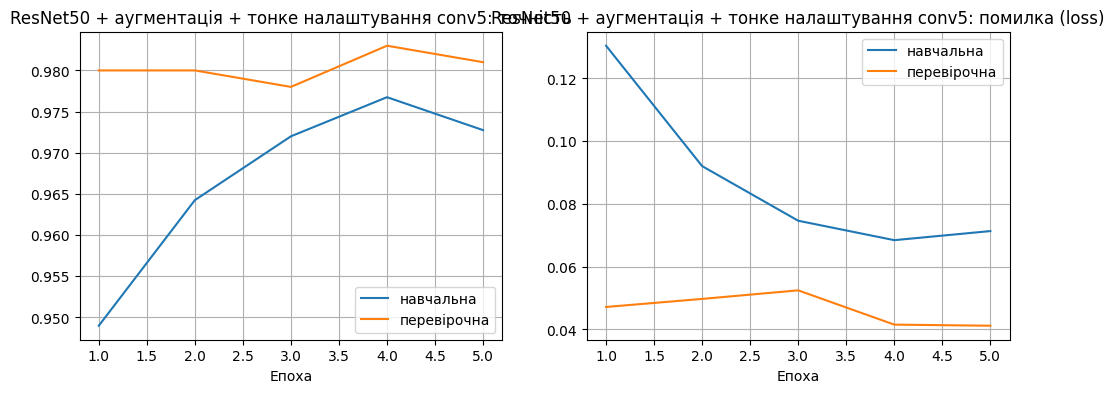

ResNet50 + аугментація + тонке налаштування conv5: точність на тестових даних 97.70%


In [15]:
model_ft1 = fine_tune(model_aug, None, 1, 'ResNet50 + аугментація + тонке налаштування conv5')

## Порівняння і збереження найкращої моделі на Google Диск

In [16]:
table = pd.DataFrame(results)
print(table.round(2))

candidates = [('без аугментації', model_noaug), ('з аугментацією', model_aug), ('тонке налаштування conv5', model_ft1)]
best_title, best_model = max(candidates, key=lambda t: t[1].evaluate(test_generator, steps=len(test_generator), verbose=0)[1])
print('Найкраща модель:', best_title)

save_dir = '/content/drive/MyDrive/Lab10_models'
os.makedirs(save_dir, exist_ok=True)
best_model.save(os.path.join(save_dir, 'resnet50_aug_best.h5'), include_optimizer=False)
table.to_csv(os.path.join(save_dir, 'resnet50_aug_best_results.csv'), index=False)
!ls -lh {save_dir}

                                              модель  навчальна, %  \
0                           ResNet50 без аугментації         96.95   
1                            ResNet50 з аугментацією         94.63   
2  ResNet50 + аугментація + тонке налаштування conv5         97.28   

   перевірочна, %  тестова, %  
0            97.6        96.9  
1            97.7        96.3  
2            98.1        97.7  


Найкраща модель: тонке налаштування conv5
total 286M
-rw------- 1 root root 102M Oct 31 11:36 inceptionv3_aug_best.h5
-rw------- 1 root root  412 Oct 31 11:36 inceptionv3_aug_best_results.csv
-rw------- 1 root root  95M Oct 31 11:57 resnet50_aug_best.h5
-rw------- 1 root root  399 Oct 31 11:57 resnet50_aug_best_results.csv
-rw------- 1 root root  90M Oct 31 11:17 vgg16_aug_best.h5
-rw------- 1 root root  627 Oct 31 11:17 vgg16_aug_best_results.csv


## Розпізнавання власних зображень (ті самі, що в лабораторних роботах 7-9)

In [17]:
img_dirs = glob.glob('/content/drive/MyDrive/**/images_cats_dogs', recursive=True)
print(img_dirs)
assert img_dirs, 'Папку images_cats_dogs не знайдено на Google Диску'
for f in glob.glob(os.path.join(img_dirs[0], '*.jpg')):
    shutil.copy(f, '/content/')
print(len(glob.glob('/content/*.jpg')), 'зображень')

['/content/drive/MyDrive/Deep learning/images_cats_dogs']
47 зображень


In [18]:
def prepare(x):
    return preprocess_input(x)


def recognize(pattern, title):
    names = sorted(glob.glob(pattern))
    cols = 5
    rows = (len(names) + cols - 1) // cols
    plt.figure(figsize=(3 * cols, 3.4 * rows), dpi=60)
    correct = 0
    for i, fn in enumerate(names):
        img = load_img(fn, target_size=(img_width, img_height))
        x = np.expand_dims(prepare(img_to_array(img)), axis=0)
        p = float(best_model.predict(x, verbose=0)[0][0])     # ймовірність класу dogs
        pred = 'dog' if p > 0.5 else 'cat'
        true = 'dog' if 'dog' in os.path.basename(fn) else 'cat'
        correct += pred == true
        conf = p if pred == 'dog' else 1 - p
        print(f"{os.path.basename(fn)}: правильно - {true}, мережа - {pred} ({conf*100:.1f}%) {'✓' if pred == true else '✗'}")
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"{os.path.basename(fn)}\n{pred} ({conf*100:.1f}%)", color='green' if pred == true else 'red')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()
    print(f"Правильно розпізнано: {correct} з {len(names)}")

cat_01.jpg: правильно - cat, мережа - cat (98.8%) ✓
cat_02.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_03.jpg: правильно - cat, мережа - cat (99.5%) ✓
cat_04.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_05.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
cat_07.jpg: правильно - cat, мережа - cat (88.2%) ✓
cat_08.jpg: правильно - cat, мережа - dog (74.0%) ✗
cat_09.jpg: правильно - cat, мережа - dog (72.5%) ✗
cat_10.jpg: правильно - cat, мережа - cat (82.5%) ✓


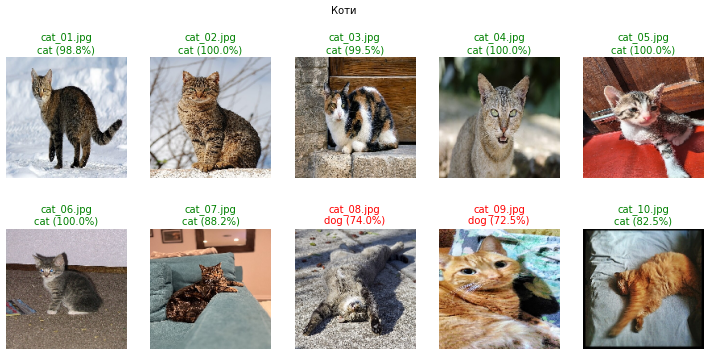

Правильно розпізнано: 8 з 10
dog_01.jpg: правильно - dog, мережа - dog (91.1%) ✓
dog_02.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_03.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_04.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_05.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_07.jpg: правильно - dog, мережа - dog (99.8%) ✓
dog_08.jpg: правильно - dog, мережа - dog (99.3%) ✓
dog_09.jpg: правильно - dog, мережа - dog (100.0%) ✓
dog_10.jpg: правильно - dog, мережа - dog (100.0%) ✓


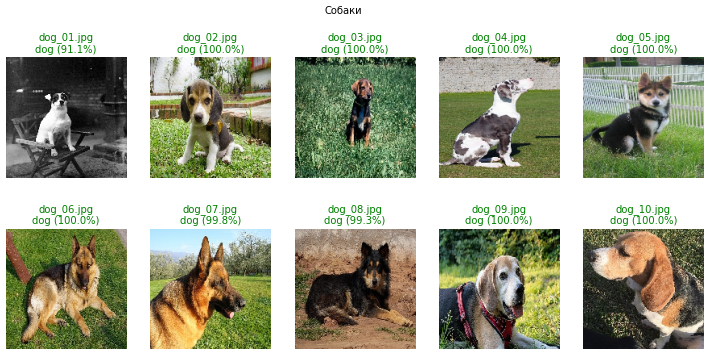

Правильно розпізнано: 10 з 10


In [19]:
recognize('cat_*.jpg', 'Коти')
recognize('dog_*.jpg', 'Собаки')

hard_cat_01.jpg: правильно - cat, мережа - dog (51.1%) ✗
hard_cat_02.jpg: правильно - cat, мережа - dog (98.0%) ✗
hard_cat_03.jpg: правильно - cat, мережа - cat (54.0%) ✓
hard_cat_04.jpg: правильно - cat, мережа - dog (68.5%) ✗
hard_cat_05.jpg: правильно - cat, мережа - cat (81.1%) ✓
hard_cat_06.jpg: правильно - cat, мережа - cat (99.7%) ✓
hard_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_08.jpg: правильно - cat, мережа - cat (100.0%) ✓
hard_cat_09.jpg: правильно - cat, мережа - dog (93.0%) ✗
hard_cat_10.jpg: правильно - cat, мережа - dog (52.7%) ✗
hard_dog_01.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_02.jpg: правильно - dog, мережа - dog (93.9%) ✓
hard_dog_03.jpg: правильно - dog, мережа - dog (91.7%) ✓
hard_dog_04.jpg: правильно - dog, мережа - dog (99.0%) ✓
hard_dog_05.jpg: правильно - dog, мережа - dog (70.2%) ✓
hard_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_07.jpg: правильно - dog, мережа - dog (100.0%) ✓
hard_dog_08.jpg: правильно

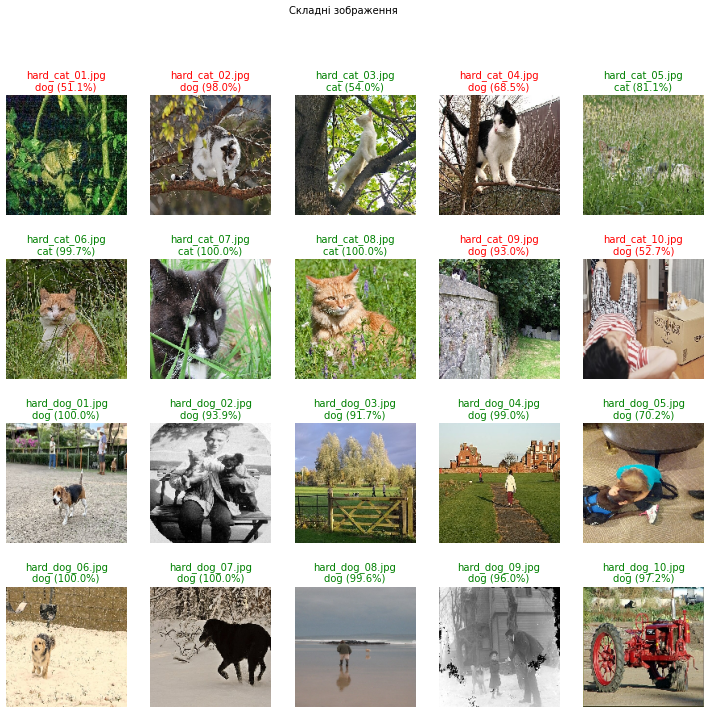

Правильно розпізнано: 15 з 20


In [20]:
recognize('hard_*.jpg', 'Складні зображення')

crop_cat_02.jpg: правильно - cat, мережа - cat (99.7%) ✓
crop_cat_03.jpg: правильно - cat, мережа - dog (89.1%) ✗
crop_cat_05.jpg: правильно - cat, мережа - cat (89.8%) ✓
crop_cat_06.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_07.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_cat_08.jpg: правильно - cat, мережа - cat (100.0%) ✓
crop_dog_06.jpg: правильно - dog, мережа - dog (100.0%) ✓


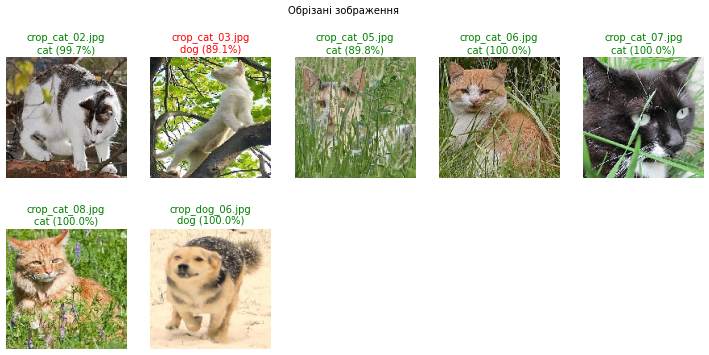

Правильно розпізнано: 6 з 7


In [21]:
recognize('crop_*.jpg', 'Обрізані зображення')